Лабораторная работа №4. Вычисления с использованием языка ассемблера

---



На языке ассемблера и на языке С разработать программы, решаюшие задачи в соответствии с вариантом. На языке ассемблера ввод параметров в программу реализовать через системный вызов read.

In [1]:
import random as rd

Variant = 14
rd.seed(Variant)

Numbers_of_problems = [i+1 for i in rd.sample(range(14),3)]
print(*Numbers_of_problems)


2 10 12


2. Написать программу, которая для заданного n вычисляет сумму:
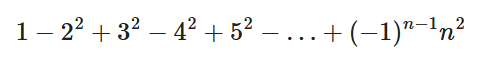

Для удобства обращения к часто используемым функциям была разработана библиотека полезных функций, подключаемая каждым файлом.
Так же для удобства использования системных вызовов read и write на языке C была так же разработана отдельная библиотека с функциями ввода и вывода чисел и строк.



In [ ]:
; библиотека необходимых функций

func_atoi:
    push rcx
    push rbx

    xor rax, rax
    xor rcx, rcx
    .loop:
        xor rbx, rbx
        mov bl, byte [rsi+rcx]
        cmp bl, 48
        jl .end
        cmp bl, 57
        jg .end

        sub bl, 48
        add rax, rbx
        mov rbx, 10
        mul rbx
        inc rcx
        jmp .loop

    .end:
        cmp rcx, 0
        je .restore
        mov rbx, 10
        div rbx

    .restore:
        pop rbx
        pop rcx
        ret

int_input_keyboard:
    push rax
    push rdi
    push rdx

    mov rax, 0
    mov rdi, 0
    mov rdx, 255
    syscall

    pop rdx
    pop rdi
    pop rax
    ret

input_keyboard:
    push rax
    push rdi
    push rdx

    mov rax, 0
    mov rdi, 0
    mov rdx, 20
    syscall

    xor rcx, rcx
    .loop:
        mov al, [rsi+rcx]
        inc rcx
        cmp al, 0x0A
        jne .loop
    dec rcx
    mov byte [rsi+rcx], 0

    pop rdx
    pop rdi
    pop rax
    ret

print_itoa:
    push rbx
    push rdi
    push rsi
    push rcx
    push rdx
    push r8

    mov r8, rsi

    cmp rax, 0
    jge .positive
    push rax

    push '-'
    mov rax, 1
    mov rdi, 1
    mov rsi, rsp
    mov rdx, 1
    syscall
    pop rax

    pop rax
    neg rax

    .positive:
        xor rbx, rbx
        mov rbx, 10
        xor rcx, rcx
        @@:
            xor rdx, rdx
            div rbx
            add rdx, '0'
            mov [r8 + rcx], dl
            inc rcx
            cmp rax, 0
            ja @b

        @@:
            dec rcx
            mov rax, r8
            add rax, rcx
            mov rdi, 1
            mov rsi, rax
            mov rax, 1
            mov rdx, 1
            push rcx
            syscall
            pop rcx
            cmp rcx, 0
            ja @b

    push 10
    mov rax, 1
    mov rdi, 1
    mov rsi, rsp
    mov rdx, 1
    syscall
    pop rax

    pop r8
    pop rdx
    pop rcx
    pop rsi
    pop rdi
    pop rbx
    ret

len_str:
    push rdx
    mov rdx, rax
    .iter:
        cmp byte [rax], 0
        je .next
        inc rax
        jmp .iter
    .next:
        sub rax, rdx
        pop rdx
        ret

print_str:
    push rax
    push rdi
    push rdx
    push rcx
    mov rax, rsi
    call len_str
    mov rdx, rax
    mov rax, 1
    mov rdi, 1
    syscall
    pop rcx
    pop rdx
    pop rdi
    pop rax
    ret

new_line:
    push rax
    push rdi
    push rsi
    push rdx
    push rcx
    mov rax, 0xA
    push rax
    mov rdi, 1
    mov rsi, rsp
    mov rdx, 1
    mov rax, 1
    syscall
    pop rax
    pop rcx
    pop rdx
    pop rsi
    pop rdi
    pop rax
    ret

exit:
    mov rax, 60
    mov rdi, 0
    syscall



In [ ]:
format ELF64

public _start
public sum_of_series

include 'funcs.asm'

section '.bss' writable
    msg rb 20
    result rb 20

section '.text' executable
    _start:
        mov rsi, msg
        call input_keyboard
        call func_atoi
        call sum_of_series

        mov rsi, result
        call print_itoa
        jmp exit

; Вход:  rax = n
; Выход: rax = итоговая сумма ряда
sum_of_series:
    push rcx
    push rdx
    push r8
    push r9
    push rdi

    xor rcx, rcx
    xor r8, r8
    xor rdi, rdi
    mov rdi, 2
    mov r8, rax ; n
    xor rax, rax ; накопитель
    .loop:
        inc rcx
        push rax

        mov rax, rcx
        mul rcx ; rax = rcx * rcx
        mov r9, rax ; r9 = k²

        mov rax, rcx
        xor rdx, rdx
        div rdi ; rdx = остаток от деления k на 2

        pop rax ; Восстанавливаем сумму в rax
        cmp rdx, 0
        je .even
        add rax, r9 ; для нечетных
        jmp .next
        .even:
            sub rax, r9 ; для четных
        .next:
            cmp rcx, r8
            jl .loop

    pop rdi
    pop r9
    pop r8
    pop rdx
    pop rcx
    ret


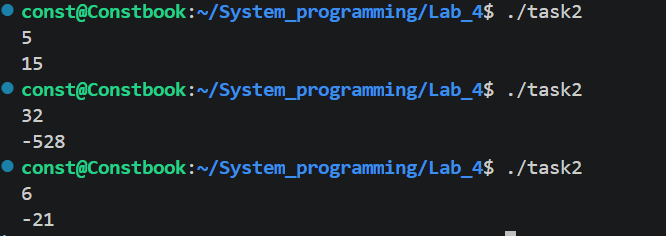

In [ ]:
#ifndef CLIB_H
#define CLIB_H

#include <unistd.h>

// Вывод null-терминированной строки в STDOUT через системный вызов write
void print_str(const char *str);

// Вывод числа типа int в STDOUT через системный вызов write
void print_int(int num);

// Преобразование строки в число (atoi) из буфера
int parse_str(const char *buf, ssize_t bytes_read);

#endif // CLIB_H


In [ ]:
#include "CLib.h"

void print_str(const char* str) {
    size_t len = 0;
    while (str[len] != '\0') {
        len++;
    }
    write(STDOUT_FILENO, str, len);
}

void print_int(int num) {
    char buf[32];
    int pos = 0;
    int is_negative = 0;

    if (num == 0) {
        write(STDOUT_FILENO, "0", 1);
        return;
    }

    if (num < 0) {
        is_negative = 1;
        num = -num;
    }

    while (num > 0) {
        buf[pos++] = '0' + (num % 10);
        num /= 10;
    }

    if (is_negative) {
        buf[pos++] = '-';
    }

    for (int i = 0; i < pos / 2; i++) {
        char temp = buf[i];
        buf[i] = buf[pos - 1 - i];
        buf[pos - 1 - i] = temp;
    }

    write(STDOUT_FILENO, buf, pos);
}

int parse_str(const char* buf, ssize_t bytes_read) {
    int val = 0;
    ssize_t i = 0;

    while (i < bytes_read && (buf[i] == ' ' || buf[i] == '\t' || buf[i] == '\n' || buf[i] == '\r')) {
        i++;
    }

    if (i >= bytes_read || buf[i] < '0' || buf[i] > '9') {
        return -1;
    }

    while (i < bytes_read && buf[i] >= '0' && buf[i] <= '9') {
        val = val * 10 + (buf[i] - '0');
        i++;
    }

    return val;
}


In [ ]:
#include "CLib.h"

int main(void) {
    char input_buf[64];

    ssize_t bytes_read = read(STDIN_FILENO, input_buf, sizeof(input_buf));

    if (bytes_read <= 0) {
        print_str("Error while reading\n");
        return 1;
    }

    int n = parse_str(input_buf, bytes_read);

    if (n <= 0) {
        print_str("Error: number must be a positive integer\n");
        return 1;
    }

    int sum = 0;

    for (int x = 1; x <= n; x++) {
        int term = x * x;
        if (x % 2 != 0) {
            sum += term;
        } else {
            sum -= term;
        }
    }

    print_int(sum);
    print_str("\n");

    return 0;
}


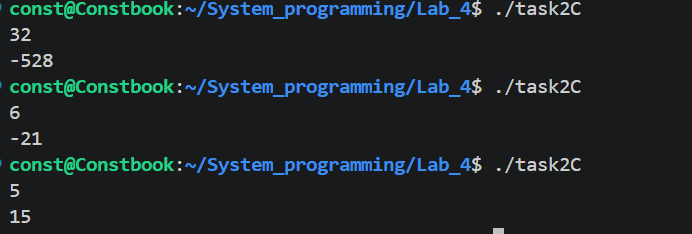

10. Разработать программу аутентификации пользователя: вводится пароль. Если пароль неверен, выдается сообщение «Невереный пароль» и пароль вводится снова. Повтор допускается до 5 раз. Если правильный пароль так и не будет введен, выдается сообщение "Неудача", если пароль подобран, то выдается сообщение "Вошли"

In [ ]:
format ELF64

public _start
public autentificate

include 'funcs.asm'

section '.bss' writable
    buf rb 255

section '.data' writable
    right db "Welcome", 0
    password db "ydlI840HsUkfns31", 0
    wrong db "wrong password, try again", 0
    failure db "access denied", 0

section '.text' executable
    _start:
        call autentificate
        jmp exit


autentificate:
    push rax
    push rbx
    push rcx
    push rsi

    xor rbx, rbx
    mov bl, 5
    .try:
        mov rsi, buf
        call input_keyboard
        mov rax, rsi
        call len_str
        push rbx
        mov rbx, rax ; длина введенного пароля
        mov rax, password
        call len_str ; в rax - длина заданного пароля
        cmp rax, rbx ; сначала сравниваем длины паролей
        pop rbx
        jne .ifwrong

        mov rcx, rax
        .loop:
            dec rcx ; идем с конца
            push rbx ; сохраняем счетчик попыток
            mov bl, byte [rsi + rcx]
            cmp bl, byte [password + rcx] ; посимвольное сравнение паролей
            pop rbx
            jne .ifwrong
            cmp rcx, 0
            ja .loop
            jmp .success ; если прошлись по всей строке и все символы совпали с правильным паролем, то успешный вход

    .ifwrong:
        dec bl
        cmp bl, 0 ; если вдруг закончились попытки, то вход запрещен
        je .fail

        mov rsi, wrong
        call print_str
        call new_line
        jmp .try ; снова пробуем ввести пароль
    .fail:
        mov rsi, failure
        call print_str
        call new_line
        jmp .restore
    .success:
        mov rsi, right
        call print_str
        call new_line
        jmp .restore

    .restore:
        pop rsi
        pop rcx
        pop rbx
        pop rax
        ret


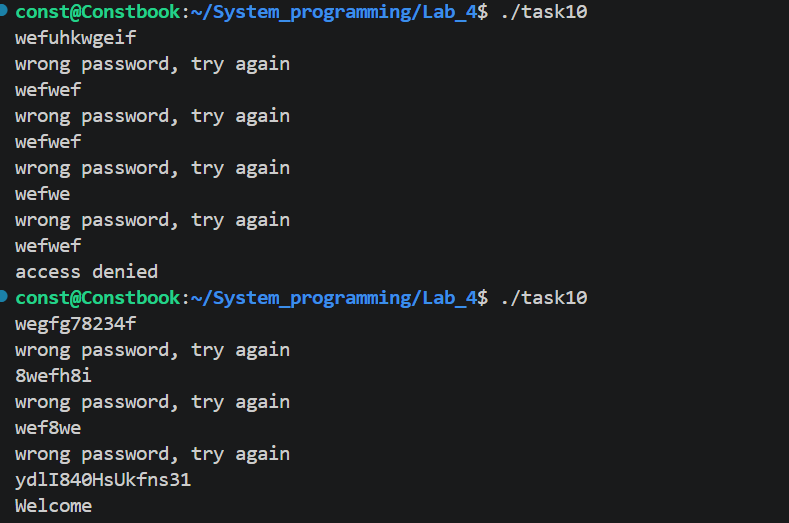

In [ ]:
#include "CLib.h"
#include <string.h>

int autentificate(const char* input, const char* password) {
    if (strcmp(input, password) == 0) {
        print_str("Welcome\n");
        return 0;
    } else {
        print_str("wrong password, try again\n");
        return -1;
    }
}

int main(void) {
    char input_buf[64];
    const char* password = "ydlI840HsUkfns31";

    int i = 0;
    int res = -1;
    while (i < 5 && res) {
        ssize_t bytes_read = read(STDIN_FILENO, input_buf, sizeof(input_buf)-1);

        if (bytes_read <= 0) {
            print_str("Error while reading\n");
            return 1;
        }

        input_buf[bytes_read - 1] = '\0';
        res = autentificate(input_buf, password);
        i++;
    }
    if (res) {
        print_str("access denied\n");
    }

    return 0;
}


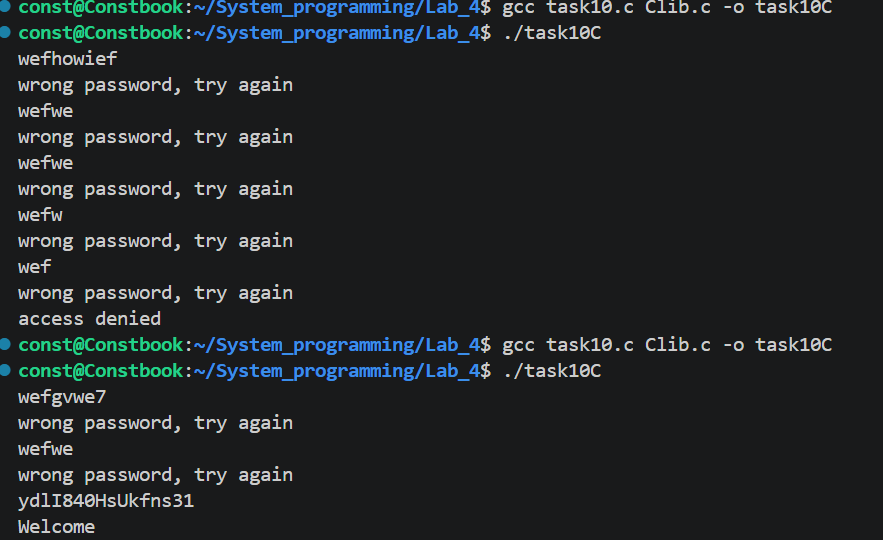

12. Реализовать функцию, которая для заданного числа n определяет, что все его цифры следуют в неубывающем порядке.

In [ ]:
format ELF64

public _start
public non_decreasing_order

include 'funcs.asm'

section '.bss' writable
    msg rb 255

section '.data' writable
    no db "no", 0
    yes db "yes", 0

section '.text' executable
    _start:
        mov rsi, msg
        call int_input_keyboard
        call non_decreasing_order
        jmp exit


non_decreasing_order:
    push rcx
    push rbx

    xor rax, rax ; предыдущая цифра
    xor rcx, rcx ; индекс текущего символа
    .loop:
        xor rbx, rbx
        mov bl, byte [rsi+rcx] ; текущий символ в строке
        cmp bl, 48 ; проверяем следующий символ на то, что он является цифрой
        jl .yes ; иначе это означает, что число закончилось, и оно прошло проверку
        cmp bl, 57
        jg .yes

        sub bl, 48 ; преобразуем ASCII-код в цифру
        cmp al, bl ; сравниваем предыдущую цифру с текущей
        ja .no ; и в случае если она больше, то это нарушает неубывание
        mov al, bl ; обновляем предыдущую цифру
        inc rcx
        jmp .loop

    .no:
        mov rsi, no
        jmp .end
    .yes:
        mov rsi, yes
        jmp .end

    .end:
        call print_str
        call new_line
        pop rbx
        pop rcx
        ret


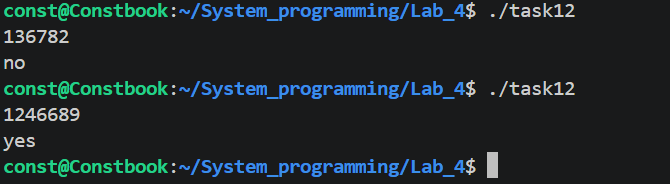

In [ ]:
#include "CLib.h"

int is_non_decreasing(int n) {
    if (n < 0) {
        n = -n;
    }

    int next_digit = 9;

    while (n > 0) {
        int current_digit = n % 10;

        if (current_digit > next_digit) {
            return 0;
        }

        next_digit = current_digit;
        n /= 10;
    }

    return 1;
}

int main(void) {
    char input_buf[64];

    ssize_t bytes_read = read(STDIN_FILENO, input_buf, sizeof(input_buf));

    if (bytes_read <= 0) {
        print_str("Error while reading\n");
        return 1;
    }

    int n = parse_str(input_buf, bytes_read);

    int ans = is_non_decreasing(n);

    if (ans) {
        print_str("yes\n");
    } else {
        print_str("no\n");
    }

    return 0;
}


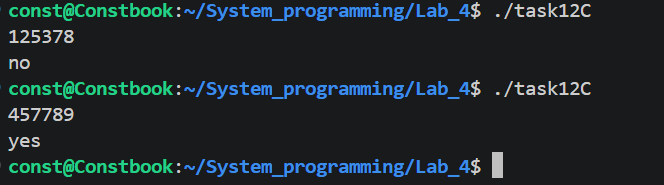